# v3 - Sile Main Canal (USGS): el mismo video, con STIV

Mide el caudal del Sile Main Canal con **STIV** (*Space-Time Image Velocimetry*) programado aqui
mismo sobre **OpenCV**, sobre **el mismo video, la misma geometria y la misma seccion que la v2**.
Es la prueba de comparacion de metodos: si todo lo que no es el algoritmo se mantiene igual, la
diferencia entre v2 y v3 es la diferencia entre LSPIV y STIV.

**Los datos de entrada se leen en modo solo lectura. Todo lo que este notebook genera se escribe en
`salidas/`.** Las lineas de codigo que cambian respecto a la v2 llevan la marca `# [v3]`.

## Que es STIV y en que se diferencia del LSPIV de la v2

El PIV correla **parches 2D** entre dos fotogramas consecutivos y devuelve un vector por parche.
STIV renuncia a la segunda dimension: fija una **linea recta orientada en la direccion del flujo**,
lee los pixeles bajo la linea en cada fotograma y los apila, una fila por fotograma. Esa imagen
apilada es la **imagen espacio-temporal (STI)**:

```
                espacio (a lo largo de la linea, aguas abajo -->)
   t = 0      | ....##....#####.......##.....                |
   t = 1      | .....##....#####.......##....                |   una fila
   t = 2      | ......##....#####.......##...                |   por fotograma
   t = 3      | .......##....#####.......##..                |
```

Una mancha de espuma que baja con la corriente dibuja en ella una **estela recta e inclinada**, y su
pendiente **es** la velocidad.

| | LSPIV (v2, pyorc) | STIV (v3) |
|---|---|---|
| Que correla | parches 2D entre 2 fotogramas | orientacion de la textura en la STI |
| Salida | campo vectorial 2D | una velocidad escalar por linea |
| Direccion del flujo | la resuelve el metodo | se le da como configuracion |
| Memoria | proporcional al video | una STI, independiente de la duracion |

---
## Que cambia respecto a v2

Es el cambio de mayor tamano de toda la serie, y es el unico en el que se sustituye el nucleo: el
caso **es** la comparacion de metodos.

| Parte | v2 (LSPIV) | v3 (STIV) | Por que |
|---|---|---|---|
| 1 | `pyorc.Video` | `cv2.VideoCapture` | pyorc deja de usarse: todo el metodo se escribe aqui |
| 2 | 2 GCPs para `CameraConfig` (modo cenital) | la escala `ESCALA` directamente | sin pyorc no hace falta construir un `CameraConfig`; la escala es la misma |
| 3 | `CameraConfig`, AOI, reproyeccion | **lineas de busqueda**: una por vertical del aforo, con `ANGULO_FLUJO` y `V_ESPERADA` | STIV mide sobre lineas, no sobre una malla; la seccion se lee aqui y no en la Parte 5 |
| 4 | `normalize` + `project` + `get_piv` | **STI** en una pasada + preparacion + **tensor de estructura** por bloques | el algoritmo |
| 4b | mascaras `velocimetry.mask.*` | **coherencia** >= 0.70 y relleno por **interpolacion lineal** | el control de calidad propio del tensor |
| 5 | `get_transect` + `get_q` + `get_river_flow` | **trapecios** sobre las mismas 13 verticales | sin pyorc; misma seccion, mismo `V_CORR` |

**Lo que no cambia:** el video de entrada (el mismo `SMC_estabilizado.mkv`), las filas de las lineas
de agua y la escala, las columnas 600-3400, los 250 fotogramas, la seccion del CSV, `V_CORR` = 0.92,
el modulo `benchmark` (Parte 6) y la comparacion con el aforo (Parte 7).

> Diferencia con `casos/03_smc_stiv`: aquel notebook usa su propio video estabilizado
> (`SMC_estabilizado_stiv.mkv`, de `estabilizar_stiv.py`). Aqui se mantiene el de la v2, porque el
> video no es lo que cambia entre versiones.

---
## Parte 0 - Rutas de trabajo

Todas las rutas son relativas a esta carpeta, que es desde donde se ejecuta el notebook. El video es
el mismo de la v2 (ver alli como se genera). Aqui **solo hay rutas**: los datos de validacion
aparecen por primera vez en la Parte 7.

In [1]:
from pathlib import Path

import benchmark  # modulo local (benchmark.py, en esta misma carpeta)

# --- Entradas (nunca se modifican) ---
DIR_DATOS = Path("../../datos/USGS")
ARCHIVO_SECCION = DIR_DATOS / "Station_Stage_SileCanal.csv"          # progresiva y calado
ARCHIVO_PIV_USGS = DIR_DATOS / "SMC_PIV_results.mat"                 # LSPIV del USGS, Parte 7
# Video ya estabilizado (FFV1 sin perdida), compartido con casos/02_smc_pyorc.
ARCHIVO_VIDEO = Path("../../casos/02_smc_pyorc/entradas/SMC_estabilizado.mkv")

# --- Salidas ---
DIR_SALIDA = Path("salidas")
# exist_ok=True evita el error si la carpeta ya existe de una ejecucion anterior.
DIR_SALIDA.mkdir(exist_ok=True)

SALIDA_CONFIG = DIR_SALIDA / "config.json"                 # [v3] configuracion congelada
SALIDA_PERFIL = DIR_SALIDA / "perfil_velocidades.csv"      # [v3] velocidad vertical a vertical
SALIDA_RESUMEN = DIR_SALIDA / "caudal_resumen.csv"         # tabla final de caudales
SALIDA_BENCHMARK = DIR_SALIDA / "benchmark_recursos.csv"   # coste de cada etapa

# Se vacian las mediciones por si el notebook se reejecuta sin reiniciar el kernel.
benchmark.reiniciar()

print("Datos de entrada:", DIR_DATOS)
print("Salidas en:      ", DIR_SALIDA)
# Se comprueba de una vez que las entradas existen, antes de procesar nada. Si aparece FALTA,
# el notebook se lanzo desde otra carpeta.
for entrada in (ARCHIVO_VIDEO, ARCHIVO_SECCION, ARCHIVO_PIV_USGS):
    print(f"  {'OK   ' if entrada.exists() else 'FALTA'} {entrada.name}")

Datos de entrada: ..\..\datos\USGS
Salidas en:       salidas
  OK    SMC_estabilizado.mkv
  OK    Station_Stage_SileCanal.csv
  OK    SMC_PIV_results.mat


---
## Parte 1 - Lectura del video

`cv2.VideoCapture` da acceso al video y a sus metadatos. De aqui salen la **cadencia** (para
convertir fotogramas en segundos, $\Delta t = 1/\mathrm{fps}$) y un fotograma en color sobre el que
comprobar la geometria.

Dimensiones del fotograma: (2160, 3840, 3)
FPS del video: 30.0150  ->  DT = 33.317 ms
Fotogramas en el video: 251


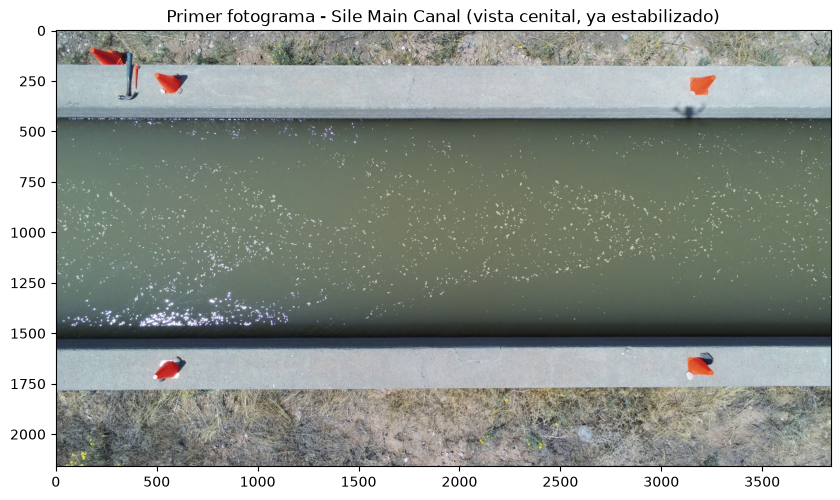

In [2]:
import cv2                        # [v3] sustituye a pyorc
import matplotlib.pyplot as plt
import numpy as np                # [v3] se necesita desde aqui

# [v3] OpenCV en vez de pyorc.Video: los metadatos y el primer fotograma.
cap = cv2.VideoCapture(str(ARCHIVO_VIDEO))
FPS = cap.get(cv2.CAP_PROP_FPS)
N_TOTAL = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
ok, frame_bgr = cap.read()
cap.release()
DT = 1.0 / FPS                    # [v3] intervalo entre fotogramas: entra en la velocidad
# OpenCV lee en BGR; matplotlib espera RGB.
frame = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

# Forma (filas, columnas, canales): las filas son la altura y las columnas el ancho.
print(f"Dimensiones del fotograma: {frame.shape}")
print(f"FPS del video: {FPS:.4f}  ->  DT = {DT * 1000:.3f} ms")                    # [v3]
print(f"Fotogramas en el video: {N_TOTAL}")                                         # [v3]

plt.figure(figsize=(10, 6))
plt.imshow(frame)
plt.title("Primer fotograma - Sile Main Canal (vista cenital, ya estabilizado)")
plt.savefig(DIR_SALIDA / "fig1_fotograma.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 2 - Puntos de control: de pixeles a metros

Los mismos dos puntos que en la v2, sobre las dos lineas de agua. En una vista cenital la
relacion entre pixeles y metros es una escala: sin pyorc ya no hace falta pasarselos a una
`CameraConfig`, basta con la regla de tres

$$ e \;[\mathrm{m/px}] \;=\; \frac{B}{f_{\mathrm{inf}} - f_{\mathrm{sup}}} $$

**Sigue siendo la constante mas influyente del notebook**: toda la velocidad es proporcional a $e$.

Ancho del canal en la imagen: 1025 px
Escala resultante:            1.784 mm/px
Incertidumbre si la linea de agua se lee con 5 px de error: 0.49 % en el caudal


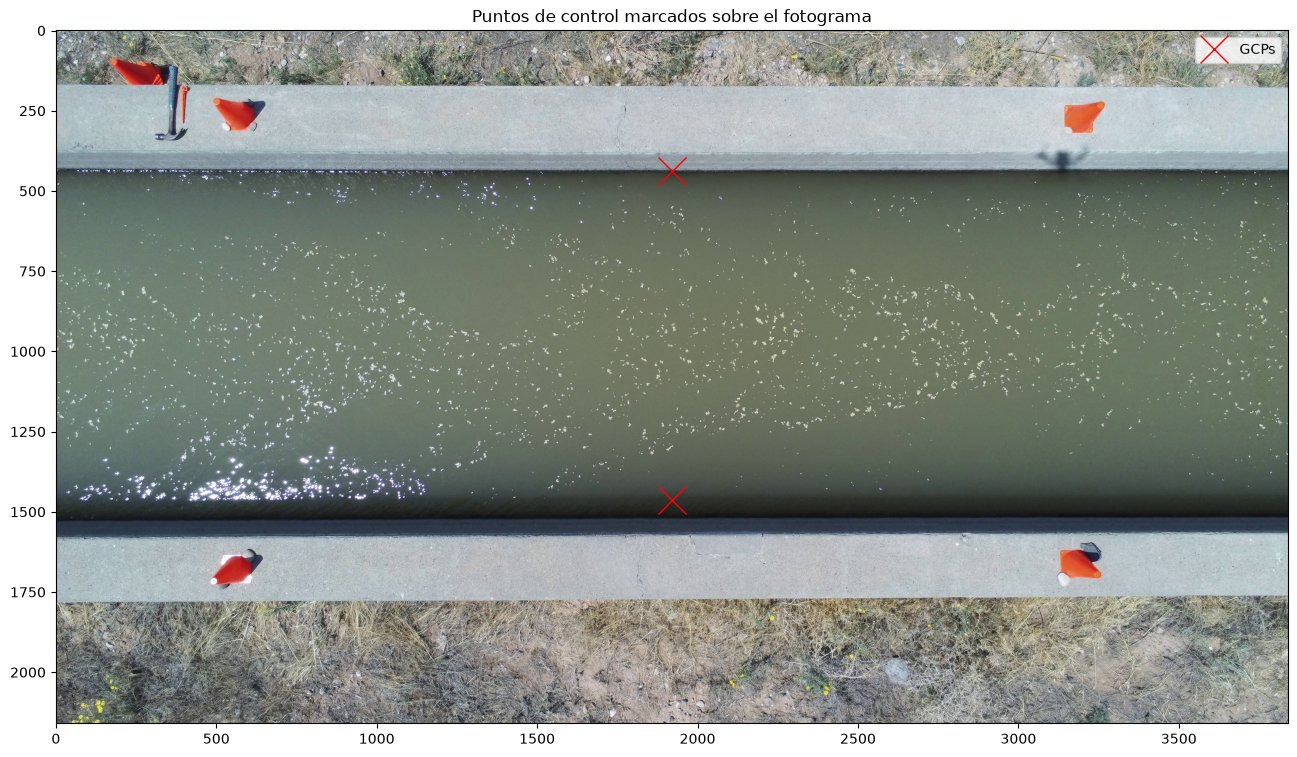

In [3]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Los dos puntos de control y la distancia real entre ellos
# ---------------------------------------------------------------------------------------
# Columna de la imagen sobre la que se leen las dos lineas de agua: el centro del fotograma,
# lejos de los bordes, donde la distorsion de lente es minima.
COLUMNA_GCP = 1920
# Fila de la linea de agua contra el muro superior.
FILA_AGUA_SUP = 438
# Fila de la linea de agua contra el muro inferior. Aqui no hay escalon de brillo (el
# hormigon queda en sombra y se confunde con el agua), asi que se lee por el criterio fisico
# de que el agua se mueve y el hormigon no: la desviacion tipica temporal por fila, sobre las
# columnas 600-3400, cae de 7.1 a 1.3 niveles de gris entre las filas 1460 y 1465 y cruza el
# punto medio en la 1463.
FILA_AGUA_INF = 1463
# Ancho real de la lamina de agua entre esas dos lineas.  (obtenido del dataset)
ANCHO_CANAL = 1.8288          # m, 6 ft exactos
# ---------------------------------------------------------------------------------------

# [v3] Ya no se construye el diccionario de GCPs de pyorc: los dos puntos solo fijan la escala.
puntos_control = [[COLUMNA_GCP, FILA_AGUA_SUP], [COLUMNA_GCP, FILA_AGUA_INF]]

ANCHO_CANAL_PX = FILA_AGUA_INF - FILA_AGUA_SUP
ESCALA = ANCHO_CANAL / ANCHO_CANAL_PX                          # m/px de la imagen original
print(f"Ancho del canal en la imagen: {ANCHO_CANAL_PX} px")
print(f"Escala resultante:            {ESCALA * 1000:.3f} mm/px")
print(f"Incertidumbre si la linea de agua se lee con 5 px de error: "
      f"{100 * 5 / ANCHO_CANAL_PX:.2f} % en el caudal")

plt.figure(figsize=(16, 9))
plt.imshow(frame)
# zip(*puntos) separa la lista de pares en dos secuencias (columnas, filas);
# el * delante las pasa a plot como los argumentos x e y.
plt.plot(*zip(*puntos_control), "rx", markersize=20, label="GCPs")                  # [v3]
plt.legend()
plt.title("Puntos de control marcados sobre el fotograma")
plt.savefig(DIR_SALIDA / "fig2_puntos_control.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 3 - Lineas de busqueda

### Una linea por vertical del aforo

La seccion del CSV del aforo, la misma de la v2, se lee ahora aqui y no en la Parte 5: en STIV las
verticales son las **lineas de busqueda**. Asi cada velocidad tiene su pareja exacta en el aforo y la
integracion reproduce el mismo convenio *mid-section*. La fila de cada estacion sale de la escala,
$f_i = f_{\mathrm{sup}} + s_i/e$, y las lineas corren a lo largo del canal entre las columnas
`COLUMNA_INI` y `COLUMNA_FIN` (las mismas del area de interes de la v2), giradas `ANGULO_FLUJO`.

Las verticales de calado cero son los extremos: caen sobre la propia linea de agua, no aportan
caudal y no se miden; se les **impone** $v = 0$.

### El paso de muestreo

La STI no se lee pixel a pixel: se muestrea la linea cada $\Delta s$ pixeles. El agua avanza
$d = u\,\Delta t / e \approx 18$ px por fotograma; con un pixel por muestra las estelas quedarian a
87 grados, casi horizontales, donde un error de angulo pesa 19 veces mas que a 45 grados
($\delta u/u = \delta\theta / \sin\theta\cos\theta$). La regla es $\Delta s = d$, y por eso la
configuracion pide una **velocidad esperada** a ojo, no un paso: cerca del optimo la curva es tan
plana que equivocarse un 30 % apenas cambia nada.

Antes de submuestrear hay que filtrar paso bajo (antialias) con $\sigma = \Delta s/2$. El filtro es
isotropo a proposito: promediar tambien a traves de la linea le da una anchura efectiva que suprime
la turbulencia de pequena escala.

 Progresiva  Prof
       0.00 0.000
       0.15 1.073
       0.30 1.073
       0.46 1.073
       0.61 1.073
       0.76 1.073
       0.91 1.073
       1.07 1.073
       1.22 1.073
       1.37 1.073
       1.52 1.073
       1.68 1.073
       1.83 0.000

Area de la seccion del CSV: 1.8026 m2
Desplazamiento esperado: 17.74 px/fotograma -> DS = 18 px, sigma antialias = 9.0 px, estelas a 44.6 grados
13 lineas de 155 muestras (4.98 m de canal cada una)


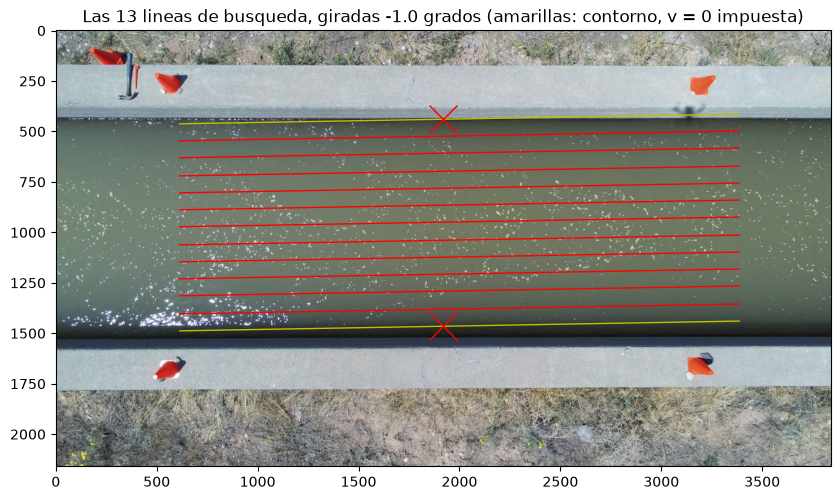

In [4]:
import pandas as pd

# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Lineas de busqueda                                              [v3]
# ---------------------------------------------------------------------------------------
# Tramo de columnas sobre el que se muestrea cada linea: el mismo 600-3400 del area de
# interes de la v2, lejos de los bordes, donde la lente del dron distorsiona mas.
COLUMNA_INI, COLUMNA_FIN = 600, 3400
# Angulo de las lineas respecto a las filas de la imagen: la direccion del flujo, que STIV
# necesita de antemano. La figura de abajo dibuja las lineas con este angulo para comprobarlo.
ANGULO_FLUJO = -1.0           # grados
# Orden de magnitud de la velocidad superficial, a ojo: de aqui sale el paso de muestreo.
V_ESPERADA = 0.95             # m/s
# ---------------------------------------------------------------------------------------

# La seccion del aforo: Progresiva (m desde la orilla izquierda) y Prof (calado, m).
seccion = pd.read_csv(ARCHIVO_SECCION)
s_transecto = seccion["Progresiva"].to_numpy(float)
prof_transecto = seccion["Prof"].to_numpy(float)
N_VERTICALES = len(s_transecto)
# Las verticales de calado nulo son los extremos: el borde del agua, no una medida.
ES_CONTORNO = prof_transecto == 0.0
AREA_SECCION = float(np.trapezoid(prof_transecto, s_transecto))
print(seccion.to_string(index=False))
print(f"\nArea de la seccion del CSV: {AREA_SECCION:.4f} m2")

# [v3] Fila de cada vertical y paso de muestreo.
filas_estaciones = FILA_AGUA_SUP + s_transecto / ESCALA
D_ESPERADO = V_ESPERADA * DT / ESCALA        # px por fotograma
DS = int(round(D_ESPERADO))                  # paso de muestreo: estelas a ~45 grados
SIGMA_ANTIALIAS = 0.5 * DS                   # filtro paso bajo obligatorio antes de submuestrear
print(f"Desplazamiento esperado: {D_ESPERADO:.2f} px/fotograma -> DS = {DS} px, "
      f"sigma antialias = {SIGMA_ANTIALIAS:.1f} px, estelas a "
      f"{np.degrees(np.arctan(D_ESPERADO / DS)):.1f} grados")


def mapa_lineas(filas, angulos_deg, ds, x0=COLUMNA_INI, x1=COLUMNA_FIN):
    """[v3] Coordenadas de muestreo de cada linea: mapx, mapy de forma (n_lineas, n_muestras)."""
    filas = np.atleast_1d(np.asarray(filas, float))
    angs = np.radians(np.atleast_1d(np.asarray(angulos_deg, float)))
    n_mu = int((x1 - x0) / ds)
    # t recorre la linea centrada en su punto medio, en pixeles
    t = (np.arange(n_mu) - (n_mu - 1) / 2) * ds
    cx = 0.5 * (x0 + x1)
    mapx = np.zeros((len(filas), n_mu), np.float32)
    mapy = np.zeros((len(filas), n_mu), np.float32)
    for i, (f, a) in enumerate(zip(filas, angs)):
        mapx[i] = cx + t * np.cos(a)
        mapy[i] = f + t * np.sin(a)
    return mapx, mapy


mapx, mapy = mapa_lineas(filas_estaciones, np.full(N_VERTICALES, ANGULO_FLUJO), DS)
print(f"{mapx.shape[0]} lineas de {mapx.shape[1]} muestras "
      f"({mapx.shape[1] * DS * ESCALA:.2f} m de canal cada una)")

plt.figure(figsize=(10, 6))
plt.imshow(frame)
# [v3] Las lineas de busqueda en lugar del area de interes de la v2.
for i in range(N_VERTICALES):
    plt.plot(mapx[i], mapy[i], "y-" if ES_CONTORNO[i] else "r-", lw=1)
plt.plot(*zip(*puntos_control), "rx", markersize=20, label="GCPs")
plt.title(f"Las {N_VERTICALES} lineas de busqueda, giradas {ANGULO_FLUJO:+.1f} grados "
          "(amarillas: contorno, v = 0 impuesta)")
plt.savefig(DIR_SALIDA / "fig3_lineas_busqueda.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4 - Velocidades superficiales con STIV

### Construir la STI, en una sola pasada

Para cada fotograma: gris, antialias, y `cv2.remap` bilineal en las coordenadas de todas las lineas
a la vez. Nunca hay mas de un fotograma en memoria.

### Prepararla

Dos cosas de la STI no son senal: el **fondo estatico** de cada muestra (rayas verticales, que el
tensor leeria como velocidad cero) y el **parpadeo global** de cada fotograma (rayas horizontales,
velocidad infinita). Se quitan restando la media temporal de cada muestra y la media espacial de cada
fotograma, y se divide por la desviacion tipica global. Es el equivalente del `normalize` de la v2.

### Medir la pendiente: el tensor de estructura

Con las derivadas $I_x$ (espacio) e $I_t$ (tiempo) se forma
$J = \begin{pmatrix} \sum I_x^2 & \sum I_x I_t \\ \sum I_x I_t & \sum I_t^2 \end{pmatrix}$. El
autovector del autovalor **menor** apunta a lo largo de las estelas; si es $(e_x, e_t)$, la pendiente
es $m = e_x/e_t$ muestras por fotograma, con signo, y la velocidad
$u = m\,\Delta s\,e / \Delta t$. La **coherencia**
$C = \sqrt{(J_{xx}-J_{tt})^2 + 4J_{xt}^2}/(J_{xx}+J_{tt}) \in [0,1]$ dice si hay una orientacion
dominante.

Un tensor sobre la STI entera dejaria que un parche brillante decidiera por toda la linea. Por eso se
resuelve **por bloques con 50 % de solape** y se combinan con una **mediana ponderada por
coherencia**.

In [5]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Cuanto video se procesa y parametros del estimador              [v3]
# ---------------------------------------------------------------------------------------
# 250 fotogramas a 30 fps son 8.3 s de video, los mismos que en la v2.
N_FRAMES = 250
# Lado del bloque de STI sobre el que se resuelve un tensor (~2 s y ~1.2 m de canal).
LADO_BLOQUE = 64
# Coherencia minima para que un bloque entre en la mediana ponderada.
COH_MIN_BLOQUE = 0.50
# Suavizado gaussiano previo a las derivadas de Sobel, en pixeles de STI.
SIGMA_DERIVADA = 1.5
# ---------------------------------------------------------------------------------------


def construir_sti(archivo, mapx, mapy, n_frames, sigma):
    """[v3] Apila n_frames filas muestreadas -> STI de forma (n_lineas, n_frames, n_muestras)."""
    cap = cv2.VideoCapture(str(archivo))
    sti = np.zeros((mapx.shape[0], n_frames, mapx.shape[1]), np.float32)
    for k in range(n_frames):
        ok, fr = cap.read()
        if not ok:
            sti = sti[:, :k, :]
            break
        gris = cv2.cvtColor(fr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        # Antialias ANTES de muestrear: sin esto el submuestreo inventa orientaciones.
        gris = cv2.GaussianBlur(gris, (0, 0), sigma)
        sti[:, k, :] = cv2.remap(gris, mapx, mapy, cv2.INTER_LINEAR)
    cap.release()
    return sti


def preparar_sti(sti):
    """[v3] Quita el fondo estatico y el parpadeo global, y normaliza."""
    a = sti - sti.mean(axis=0, keepdims=True)   # fondo fijo de cada muestra (rayas verticales)
    a = a - a.mean(axis=1, keepdims=True)       # parpadeo de cada fotograma (rayas horizontales)
    d = a.std()
    return a / d if d > 0 else a


def tensor_estructura(bloque, sigma=SIGMA_DERIVADA):
    """[v3] Pendiente m (muestras/fotograma) y coherencia C de un trozo de STI."""
    g = cv2.GaussianBlur(bloque, (0, 0), sigma)
    # eje 0 = tiempo (filas), eje 1 = espacio (columnas)
    It = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    Ix = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    # se recorta el borde: Sobel contamina 2 px por el efecto de borde
    It, Ix = It[2:-2, 2:-2], Ix[2:-2, 2:-2]
    Jxx = float((Ix * Ix).sum())
    Jtt = float((It * It).sum())
    Jxt = float((Ix * It).sum())
    if Jxx + Jtt <= 0:
        return np.nan, 0.0
    # autovector del autovalor MENOR = direccion a lo largo de las estelas
    _, vec = np.linalg.eigh(np.array([[Jxx, Jxt], [Jxt, Jtt]]))
    ex, et = vec[:, 0]
    if et < 0:            # el autovector esta definido salvo signo: se orienta hacia t creciente
        ex, et = -ex, -et
    m = ex / et if et != 0 else np.nan
    coherencia = np.sqrt((Jxx - Jtt) ** 2 + 4 * Jxt ** 2) / (Jxx + Jtt)
    return m, float(coherencia)


def medir_sti(sti_p, lado=LADO_BLOQUE, coh_min=COH_MIN_BLOQUE):
    """[v3] Pendiente robusta de una STI, por bloques con solape: (m, coherencia mediana)."""
    nt, nx = sti_p.shape
    paso = lado // 2
    ms, cs = [], []
    for t0 in range(0, nt - lado + 1, paso):
        for x0 in range(0, nx - lado + 1, paso):
            m, c = tensor_estructura(sti_p[t0:t0 + lado, x0:x0 + lado])
            if np.isfinite(m):
                ms.append(m); cs.append(c)
    if not ms:
        return np.nan, 0.0
    ms, cs = np.array(ms), np.array(cs)
    coh_mediana = float(np.median(cs))
    usables = cs >= coh_min
    if usables.sum() == 0:
        return np.nan, coh_mediana
    # mediana ponderada por coherencia: los bloques nitidos pesan mas
    mm, cc = ms[usables], cs[usables]
    orden = np.argsort(mm)
    mm, cc = mm[orden], cc[orden]
    acumulado = np.cumsum(cc) / cc.sum()
    return float(mm[np.searchsorted(acumulado, 0.5)]), coh_mediana


# [v3] Unica pasada sobre el video: el bloque caro del notebook.
with benchmark.medir("Parte 4: construir las STI", n_frames=N_FRAMES):
    sti_crudo = construir_sti(ARCHIVO_VIDEO, mapx, mapy, N_FRAMES, SIGMA_ANTIALIAS)
# Las STI son pequenas (2 MB): se guardan para poder repetir la medida sin leer el video 4K.
np.save(DIR_SALIDA / "sti_crudo.npy", sti_crudo)

with benchmark.medir("Parte 4: preparar STI + tensor de estructura"):
    sti_prep = np.stack([preparar_sti(s) for s in sti_crudo])
    v_stiv = np.full(N_VERTICALES, np.nan)
    coherencia = np.full(N_VERTICALES, np.nan)
    for i in range(N_VERTICALES):
        if ES_CONTORNO[i]:
            v_stiv[i] = 0.0           # condicion de contorno: calado nulo y muro
            continue
        m, coherencia[i] = medir_sti(sti_prep[i])
        v_stiv[i] = m * DS * ESCALA / DT if np.isfinite(m) else np.nan

print(f"STI: {sti_crudo.shape[0]} lineas x {sti_crudo.shape[1]} fotogramas x "
      f"{sti_crudo.shape[2]} muestras")
print(pd.DataFrame({"vertical": np.arange(N_VERTICALES), "s_m": s_transecto,
                    "v_stiv_ms": v_stiv, "coherencia": coherencia})
      .to_string(index=False, float_format=lambda x: f"{x:8.4f}"))

  [bench] Parte 4: construir las STI: 280.1 s | CPU 494.4 s (1.8 nucleos) | RAM pico 1037 MB
  [bench] Parte 4: preparar STI + tensor de estructura: 0.1 s | CPU 0.1 s (0.8 nucleos) | RAM pico 286 MB
STI: 13 lineas x 250 fotogramas x 155 muestras
 vertical      s_m  v_stiv_ms  coherencia
        0   0.0000     0.0000         NaN
        1   0.1500     0.5539      0.5451
        2   0.3000     0.7317      0.7763
        3   0.4600     0.8367      0.9416
        4   0.6100     0.8785      0.9698
        5   0.7600     0.9591      0.9737
        6   0.9100     0.9744      0.9746
        7   1.0700     0.9437      0.9775
        8   1.2200     0.9590      0.9711
        9   1.3700     0.8957      0.9630
       10   1.5200     0.8493      0.8801
       11   1.6800     1.3175      0.6121
       12   1.8300     0.0000         NaN


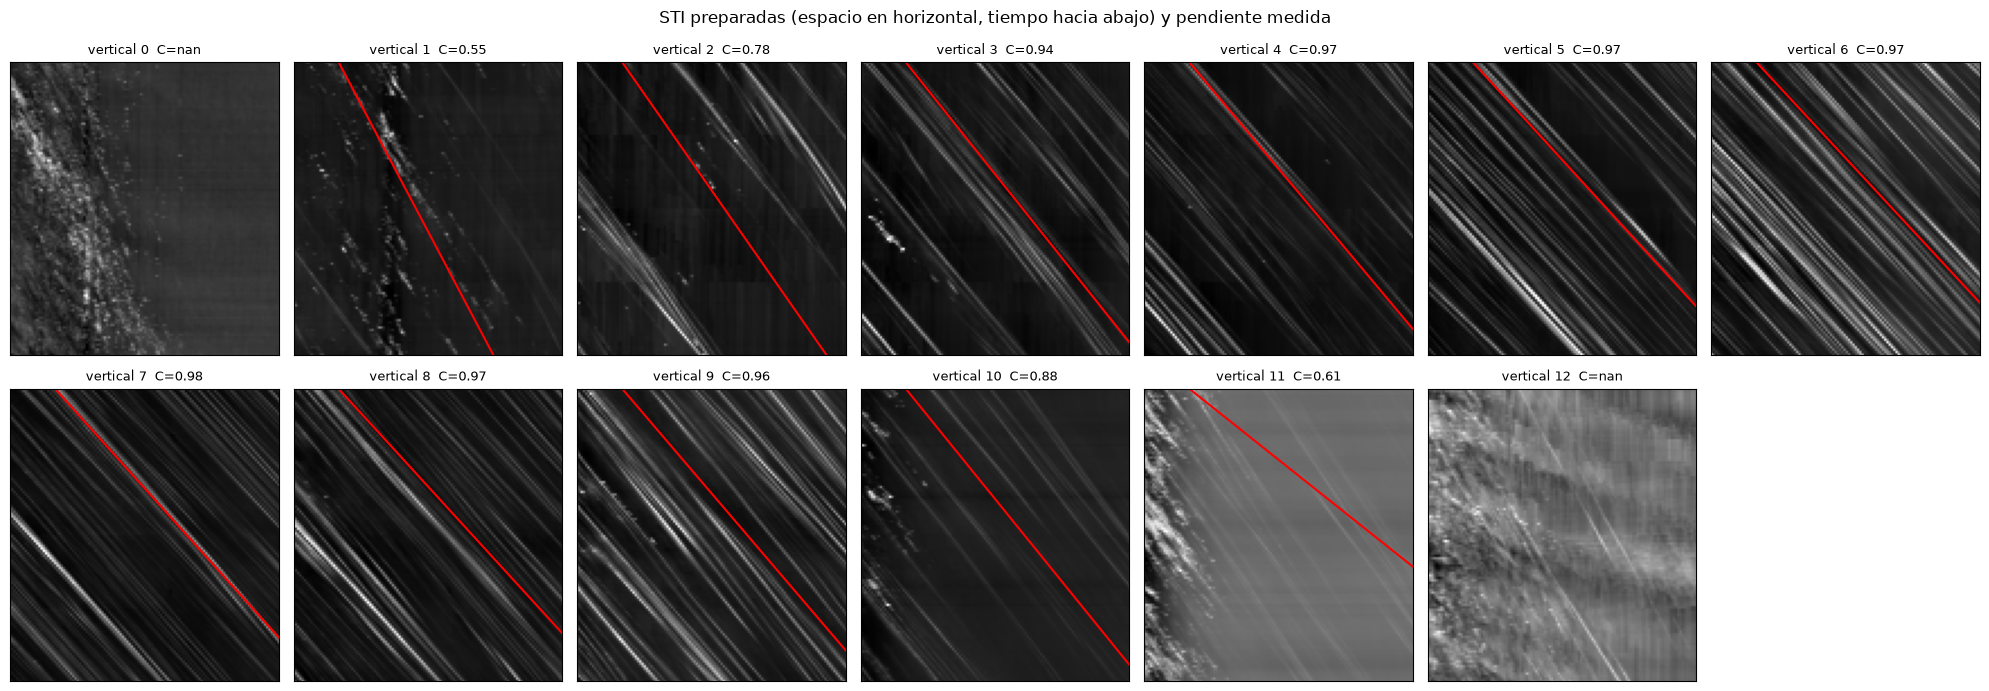

In [6]:
# [v3] Las STI de todas las verticales, con la pendiente medida dibujada encima: es lo que
# hace auditable cada numero. Junto a los muros las estelas casi desaparecen.
fig, axes = plt.subplots(2, 7, figsize=(20, 7))
for i, ax in enumerate(axes.ravel()):
    if i >= N_VERTICALES:
        ax.axis("off"); continue
    ax.imshow(sti_prep[i][:120, :120], cmap="gray", aspect="auto")
    if np.isfinite(v_stiv[i]) and not ES_CONTORNO[i]:
        m = v_stiv[i] * DT / (DS * ESCALA)
        ax.plot([20, 20 + 119 * m], [0, 119], "r-", lw=1.5)
    ax.set_xlim(0, 119); ax.set_ylim(119, 0)
    ax.set_title(f"vertical {i}  C={coherencia[i]:.2f}", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("STI preparadas (espacio en horizontal, tiempo hacia abajo) y pendiente medida")
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig4_sti.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 4b - Control de calidad y relleno de los huecos

El equivalente de las mascaras de la v2. Las verticales con coherencia por debajo de 0.70 se
descartan: son siempre las pegadas al hormigon, donde el agua va lenta, apenas arrastra espuma y el
muro da sombra, de modo que el tensor mide ondas y reflejos que **no viajan con la corriente**.

Los huecos se rellenan por **interpolacion lineal** entre las verticales validas (el `log_interp` de
la v2 no existe fuera de pyorc). Los ceros de los muros **no** entran como apoyo: estan donde el CSV
da calado cero y no son medidas de velocidad. Fuera del tramo medido se mantiene el valor del
extremo: la capa limite contra un muro liso es mucho mas fina que la separacion entre verticales.

In [7]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Criterio de aceptacion                                          [v3]
# ---------------------------------------------------------------------------------------
# Coherencia mediana minima para dar por buena una vertical. 0.70 equivale a que la
# orientacion dominante sea ~6 veces mas fuerte que la perpendicular. Se fija ANTES de ver
# ningun resultado.
COH_MIN_ESTACION = 0.70
# ---------------------------------------------------------------------------------------

with benchmark.medir("Parte 4b: control de calidad y relleno"):                    # [v3]
    medida = (~ES_CONTORNO) & (coherencia >= COH_MIN_ESTACION) & np.isfinite(v_stiv)
    v_eff = v_stiv.copy()
    rellenadas = np.where(~(medida | ES_CONTORNO))[0]
    v_eff[rellenadas] = np.interp(s_transecto[rellenadas], s_transecto[medida], v_stiv[medida])
v_eff_medida = np.where(medida, v_stiv, np.nan)                                    # [v3]

print(f"Verticales medidas: {int(medida.sum())} de {int((~ES_CONTORNO).sum())} interiores")
for i in rellenadas:
    print(f"  vertical {i} (s = {s_transecto[i]:.2f} m, coherencia {coherencia[i]:.3f}): "
          f"{v_stiv[i]:.3f} -> {v_eff[i]:.3f} m/s [interpolada]")

  [bench] Parte 4b: control de calidad y relleno: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 212 MB
Verticales medidas: 9 de 11 interiores
  vertical 1 (s = 0.15 m, coherencia 0.545): 0.554 -> 0.732 m/s [interpolada]
  vertical 11 (s = 1.68 m, coherencia 0.612): 1.318 -> 0.849 m/s [interpolada]


---
## Parte 5 - Caudal sobre la seccion

La misma seccion y el mismo `V_CORR` que en la v2; lo unico que cambia es quien integra. Con
el calado $h_i$ de cada vertical, $q_i = V_{CORR}\,u_i\,h_i$ y el caudal se integra por trapecios
sobre las progresivas, que es la misma cuenta que hacia pyorc sobre estas 13 verticales.

  [bench] Parte 5: integracion del caudal: 0.0 s | CPU 0.0 s (0.0 nucleos) | RAM pico 213 MB


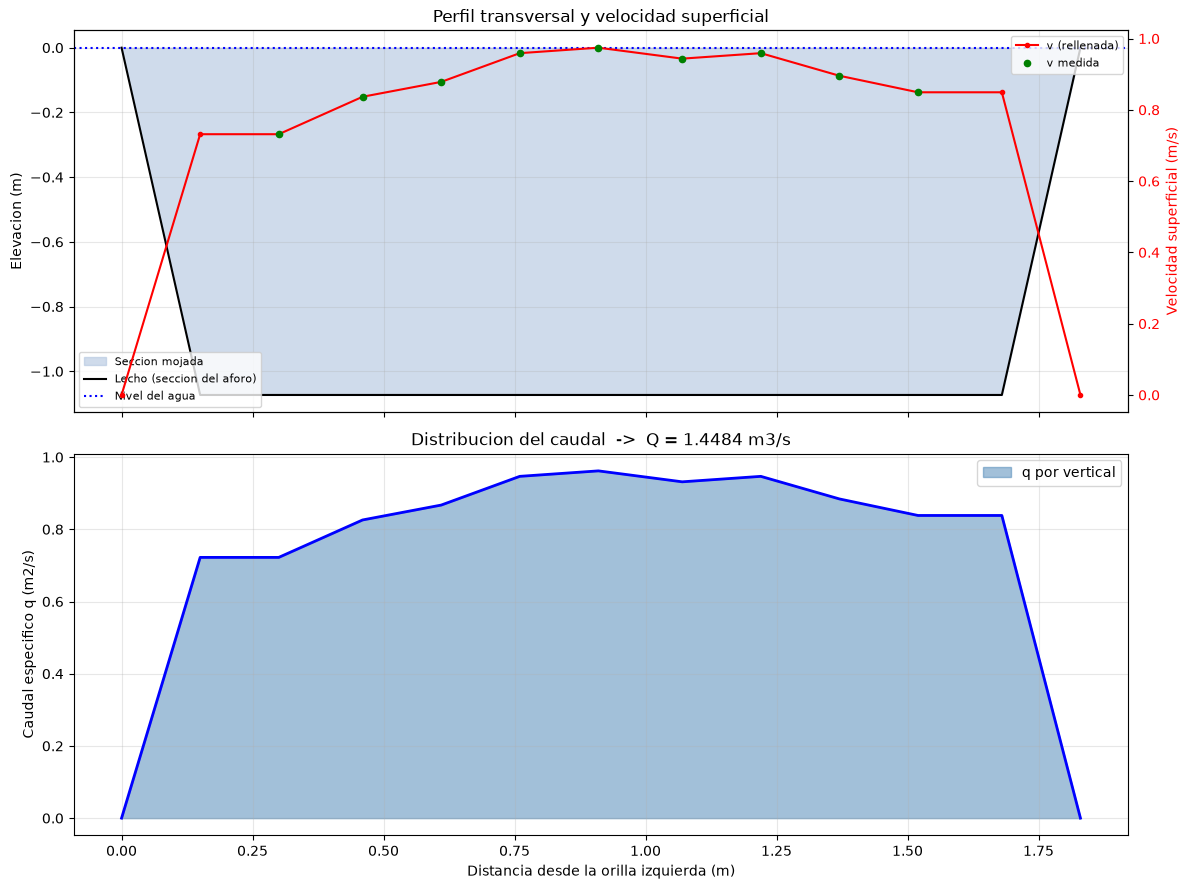

In [8]:
# ---------------------------------------------------------------------------------------
#  >>> AJUSTABLE <<<  Paso de velocidad superficial a media en la vertical
# ---------------------------------------------------------------------------------------
V_CORR = 0.92                 # el mismo de la v2; no se toca despues
# ---------------------------------------------------------------------------------------

with benchmark.medir("Parte 5: integracion del caudal"):                           # [v3]
    q_especifico = V_CORR * v_eff * prof_transecto                # m2/s
    Q_VIDEO = float(np.trapezoid(q_especifico, s_transecto))      # m3/s

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

# --- Panel superior: geometria de la seccion y velocidad efectiva ---
ax_z = axes[0]
ax_z.fill_between(s_transecto, -prof_transecto, 0, color="lightsteelblue", alpha=0.6,
                  label="Seccion mojada")                                            # [v3]
ax_z.plot(s_transecto, -prof_transecto, "k-", lw=1.5, label="Lecho (seccion del aforo)")
ax_z.axhline(0, color="b", ls=":", lw=1.5, label="Nivel del agua")
ax_z.set_ylabel("Elevacion (m)")
ax_z.set_title("Perfil transversal y velocidad superficial")
ax_z.legend(loc="lower left", fontsize=8)
ax_z.grid(True, alpha=0.3)

# twinx crea un segundo eje y que comparte el eje x, para superponer velocidades a las cotas.
ax_v = ax_z.twinx()
ax_v.plot(s_transecto, v_eff, "r-o", ms=3, lw=1.5, label="v (rellenada)")
# Los huecos delatan cuanta parte del perfil es interpolacion.
ax_v.plot(s_transecto, v_eff_medida, "g.", ms=9, label="v medida")
ax_v.set_ylabel("Velocidad superficial (m/s)", color="r")
ax_v.tick_params(axis="y", labelcolor="r")
ax_v.legend(loc="upper right", fontsize=8)

# --- Panel inferior: caudal especifico ---
axes[1].fill_between(s_transecto, q_especifico, alpha=0.5, color="steelblue",
                     label="q por vertical")                                          # [v3]
axes[1].plot(s_transecto, q_especifico, "b-", lw=2)
axes[1].set_xlabel("Distancia desde la orilla izquierda (m)")
axes[1].set_ylabel("Caudal especifico q (m2/s)")
axes[1].set_title(f"Distribucion del caudal  ->  Q = {Q_VIDEO:.4f} m3/s")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig5_perfil_transecto.png", dpi=110, bbox_inches="tight")
plt.show()

In [9]:
# Sin referencia: el caudal se calcula y se guarda; la comparacion es la Parte 7.
print("=" * 52)
print(f"Caudal:          {Q_VIDEO:.4f} m3/s")
print(f"Velocidad media: {Q_VIDEO / AREA_SECCION:.4f} m/s")
print(f"Verticales con velocidad medida: {int(medida.sum())} de "
      f"{int((~ES_CONTORNO).sum())} interiores (el resto, interpolacion lineal)")     # [v3]
print("=" * 52)

# El perfil vertical a vertical, para poder reanalizar sin repetir el video.
perfil = pd.DataFrame({
    "vertical": np.arange(N_VERTICALES),
    "s_m": s_transecto,
    "prof_m": prof_transecto,
    "coherencia": coherencia,                                                    # [v3]
    "v_sup_medida_ms": v_eff_medida,
    "v_sup_usada_ms": v_eff,
    "q_especifico_m2s": q_especifico,
    "origen": np.where(ES_CONTORNO, "contorno (v=0 por convenio)",
                       np.where(medida, "medida", "relleno interpolacion lineal")),   # [v3]
})
perfil.to_csv(SALIDA_PERFIL, index=False)

# [v3] La configuracion se congela en JSON: cualquier numero que cambie el caudal esta aqui.
import json
config = dict(video=str(ARCHIVO_VIDEO), n_frames=N_FRAMES, fps=FPS,
              fila_agua_sup=FILA_AGUA_SUP, fila_agua_inf=FILA_AGUA_INF,
              ancho_canal_m=ANCHO_CANAL, escala_m_px=ESCALA,
              columna_ini=COLUMNA_INI, columna_fin=COLUMNA_FIN, angulo_flujo=ANGULO_FLUJO,
              v_esperada=V_ESPERADA, ds_px=DS, sigma_antialias=SIGMA_ANTIALIAS,
              lado_bloque=LADO_BLOQUE, coh_min_bloque=COH_MIN_BLOQUE,
              sigma_derivada=SIGMA_DERIVADA, coh_min_estacion=COH_MIN_ESTACION,
              v_corr=V_CORR, caudal_m3s=Q_VIDEO)
SALIDA_CONFIG.write_text(json.dumps(config, indent=2), encoding="utf-8")
print(f"\nPerfil guardado en: {SALIDA_PERFIL}")
perfil

Caudal:          1.4484 m3/s
Velocidad media: 0.8035 m/s
Verticales con velocidad medida: 9 de 11 interiores (el resto, interpolacion lineal)

Perfil guardado en: salidas\perfil_velocidades.csv


,vertical,s_m,prof_m,coherencia,v_sup_medida_ms,v_sup_usada_ms,q_especifico_m2s,origen
0,0,0.00,0.000,NaN,NaN,0.000000,0.000000,contorno (v=0 por convenio)
1,1,0.15,1.073,0.545058,NaN,0.731652,0.722258,relleno interpolacion lineal
2,2,0.30,1.073,0.776268,0.731652,0.731652,0.722258,medida
3,3,0.46,1.073,0.941585,0.836695,0.836695,0.825951,medida
4,4,0.61,1.073,0.969771,0.878465,0.878465,0.867186,medida
5,5,0.76,1.073,0.973750,0.959067,0.959067,0.946752,medida
6,6,0.91,1.073,0.974649,0.974405,0.974405,0.961894,medida
7,7,1.07,1.073,0.977549,0.943704,0.943704,0.931587,medida
8,8,1.22,1.073,0.971108,0.959038,0.959038,0.946724,medida
9,9,1.37,1.073,0.962952,0.895678,0.895678,0.884177,medida


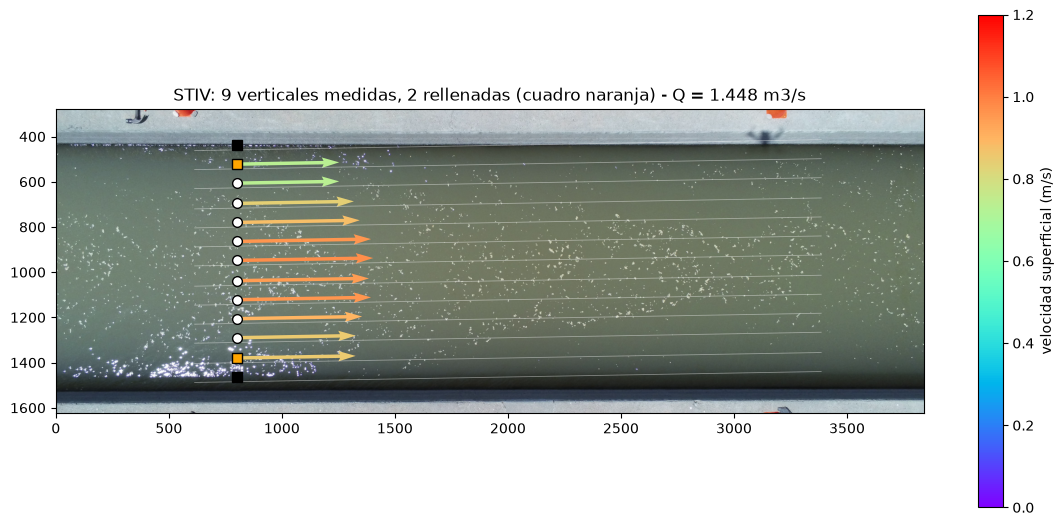

In [10]:
# [v3] Mapa final: una flecha por vertical sobre el fotograma. STIV no da campo 2D sino un
# escalar por linea, orientado segun ANGULO_FLUJO (la direccion es configuracion).
PX_POR_MS = 620               # pixeles de flecha por cada m/s, solo para que se vean
ang = np.radians(ANGULO_FLUJO)
x0 = COLUMNA_INI + 200
plt.figure(figsize=(14, 8))
plt.imshow(frame)
for i in range(N_VERTICALES):
    plt.plot(mapx[i], mapy[i], color="w", lw=0.6, alpha=0.4)
q = plt.quiver(np.full(N_VERTICALES, x0), filas_estaciones, v_eff * PX_POR_MS * np.cos(ang),
               v_eff * PX_POR_MS * np.sin(ang), v_eff, cmap="rainbow",
               norm=plt.Normalize(0.0, 1.2), angles="xy", scale_units="xy", scale=1, width=0.004)
plt.colorbar(q, label="velocidad superficial (m/s)", shrink=0.8)
for i in range(N_VERTICALES):
    # cuadro negro: contorno; circulo blanco: medida; cuadro naranja: rellenada
    marca, color = ("s", "k") if ES_CONTORNO[i] else (("o", "w") if medida[i] else ("s", "orange"))
    plt.plot(x0, filas_estaciones[i], marca, color=color, ms=7, mec="k")
plt.ylim(FILA_AGUA_INF + 160, FILA_AGUA_SUP - 160)
plt.title(f"STIV: {int(medida.sum())} verticales medidas, {len(rellenadas)} rellenadas "
          f"(cuadro naranja) - Q = {Q_VIDEO:.3f} m3/s")
plt.savefig(DIR_SALIDA / "fig6_mapa_velocidades.png", dpi=110, bbox_inches="tight")
plt.show()

---
## Parte 6 - Recursos consumidos

Columnas: **segundos** de reloj; **cpu_s** y **nucleos** (CPU sumando todos los nucleos y su cociente
con el reloj: 1.0 es un solo hilo saturado); **ram_pico_mb**, el maximo de memoria residente durante
la etapa, que es lo que decide si un video mas largo cabe; y **ram_neta_mb**, lo que queda ocupado
al terminar.

El contraste con la v2 es el dato de esta parte: LSPIV mantiene el video entero proyectado para
correlar parches (~14 GB en `get_piv`); STIV no guarda nunca mas de un fotograma, y el tensor trabaja
sobre unas STI de medio megabyte. Lo caro es decodificar y filtrar los fotogramas 4K.

Maquina donde se han medido los tiempos:
  cpu_nucleos_fisicos: 12
  cpu_nucleos_logicos: 16
  ram_total_gb: 42.7
  ram_disponible_gb: 19.1

Tiempo total medido: 280.2 s
Pico de memoria del proceso: 1037 MB


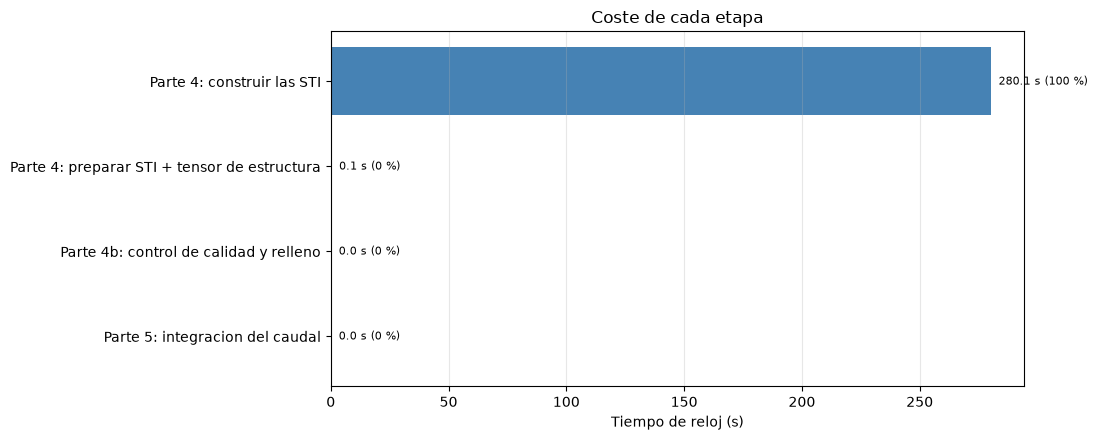

,etapa,segundos,cpu_s,nucleos,ram_pico_mb,ram_neta_mb,n_frames,pct_tiempo
0,Parte 4: construir las STI,280.10,494.41,1.77,1036.7,2.9,250.0,100.0
1,Parte 4: preparar STI + tensor de estructura,0.14,0.11,0.81,285.9,2.9,NaN,0.0
2,Parte 4b: control de calidad y relleno,0.00,0.00,0.00,212.5,0.0,NaN,0.0
3,Parte 5: integracion del caudal,0.00,0.00,0.00,212.5,0.0,NaN,0.0


In [11]:
print("Maquina donde se han medido los tiempos:")
for k, v in benchmark.entorno().items():
    print(f"  {k}: {v}")

tabla_recursos = benchmark.tabla()
tabla_recursos.to_csv(SALIDA_BENCHMARK, index=False)
print(f"\nTiempo total medido: {tabla_recursos['segundos'].sum():.1f} s")
print(f"Pico de memoria del proceso: {tabla_recursos['ram_pico_mb'].max():.0f} MB")

fig, ax = plt.subplots(figsize=(11, 4.5))
orden = tabla_recursos.sort_values("segundos")
ax.barh(orden["etapa"], orden["segundos"], color="steelblue")
ax.set_xlabel("Tiempo de reloj (s)")
ax.set_title("Coste de cada etapa")
ax.grid(axis="x", alpha=0.3)
for y, (seg, pct) in enumerate(zip(orden["segundos"], orden["pct_tiempo"])):
    ax.text(seg, y, f"  {seg:.1f} s ({pct:.0f} %)", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig7_recursos.png", dpi=110, bbox_inches="tight")
plt.show()
tabla_recursos

---
## Parte 7 - Comparacion con la referencia del dataset

Hasta aqui no se ha usado ni un solo dato de validacion. Ahora se abren las dos referencias del
data release:

1. **El aforo con FlowTracker** (ADV, por vadeo) del mismo dia: caudal total y velocidad media en la
   vertical de cada una de las 13 verticales. Medida **independiente**, incertidumbre ISO 4.2 %.
2. **El LSPIV del propio USGS** (`SMC_PIV_results.mat`, PIVlab). Corresponde al vuelo **020** y no al
   **022** que se procesa aqui: sirve para contrastar la **forma** del perfil, no punto a punto.

Y, nuevo en esta version, **el resultado de la v2** sobre el mismo video: es la comparacion de
algoritmos que motiva el caso.

**Esta es la ultima parte del notebook. No se vuelve atras a ajustar nada.**

In [12]:
# ---------------------------------------------------------------------------------------
#  Datos de validacion. Primera vez que aparecen en el notebook.
#  Aforo con FlowTracker (ADV, por vadeo) del 2020-08-17 11:17. (obtenido del dataset)
# ---------------------------------------------------------------------------------------
Q_AFORO = 1.4362              # m3/s, caudal total medido
AREA_AFORO = 1.799            # m2, area de la seccion segun el convenio mid-section
V_MEDIA_AFORO = 0.7985        # m/s, velocidad media en la seccion
V_ADV = np.array([0.0, 0.6298, 0.7973, 0.8132, 0.8121, 0.8220, 0.8518,   # m/s, media en la
                  0.8508, 0.8458, 0.8094, 0.8146, 0.7365, 0.0])         # vertical
# ---------------------------------------------------------------------------------------

error_rel = 100 * (Q_VIDEO / Q_AFORO - 1)
print("=" * 66)
print(f"  STIV (este notebook)    : {Q_VIDEO:.4f} m3/s")                              # [v3]
print(f"  Aforo FlowTracker (ADV) : {Q_AFORO:.4f} m3/s   (incertidumbre ISO 4.2 %)")
print(f"  Diferencia              : {error_rel:+.1f} %")
print(f"  Velocidad media         : {Q_VIDEO / AREA_SECCION:.4f} m/s  |  aforo {V_MEDIA_AFORO:.4f} m/s")
print("=" * 66)

# [v3] El resultado de la v2 sobre el mismo video, si se ha ejecutado.
DIR_V2 = Path("../v2_smc_lspiv/salidas")
perfil_v2 = None
if (DIR_V2 / "perfil_transecto.csv").exists():
    perfil_v2 = pd.read_csv(DIR_V2 / "perfil_transecto.csv")
    Q_V2 = float(pd.read_csv(DIR_V2 / "caudal_resumen.csv")["valor"].iloc[0])
    print(f"  v2 (LSPIV, mismo video) : {Q_V2:.4f} m3/s   ({100 * (Q_V2 / Q_AFORO - 1):+.1f} %)")

v_media_vertical = v_eff * V_CORR
comparacion = pd.DataFrame({
    "vertical": np.arange(N_VERTICALES),
    "s_m": s_transecto,
    "v_sup": v_eff,
    "v_media": v_media_vertical,
    "v_media_ADV": V_ADV,
    "dif_pct": np.where(V_ADV > 0, 100 * (v_media_vertical / np.where(V_ADV > 0, V_ADV, 1) - 1),
                        np.nan),
    "origen": perfil["origen"],
})
print(comparacion.to_string(index=False, float_format=lambda x: f"{x:8.4f}"))

  STIV (este notebook)    : 1.4484 m3/s
  Aforo FlowTracker (ADV) : 1.4362 m3/s   (incertidumbre ISO 4.2 %)
  Diferencia              : +0.9 %
  Velocidad media         : 0.8035 m/s  |  aforo 0.7985 m/s
  v2 (LSPIV, mismo video) : 1.4545 m3/s   (+1.3 %)
 vertical      s_m    v_sup  v_media  v_media_ADV  dif_pct                       origen
        0   0.0000   0.0000   0.0000       0.0000      NaN  contorno (v=0 por convenio)
        1   0.1500   0.7317   0.6731       0.6298   6.8784 relleno interpolacion lineal
        2   0.3000   0.7317   0.6731       0.7973 -15.5751                       medida
        3   0.4600   0.8367   0.7698       0.8132  -5.3420                       medida
        4   0.6100   0.8785   0.8082       0.8121  -0.4817                       medida
        5   0.7600   0.9591   0.8823       0.8220   7.3408                       medida
        6   0.9100   0.9744   0.8965       0.8518   5.2422                       medida
        7   1.0700   0.9437   0.8682      

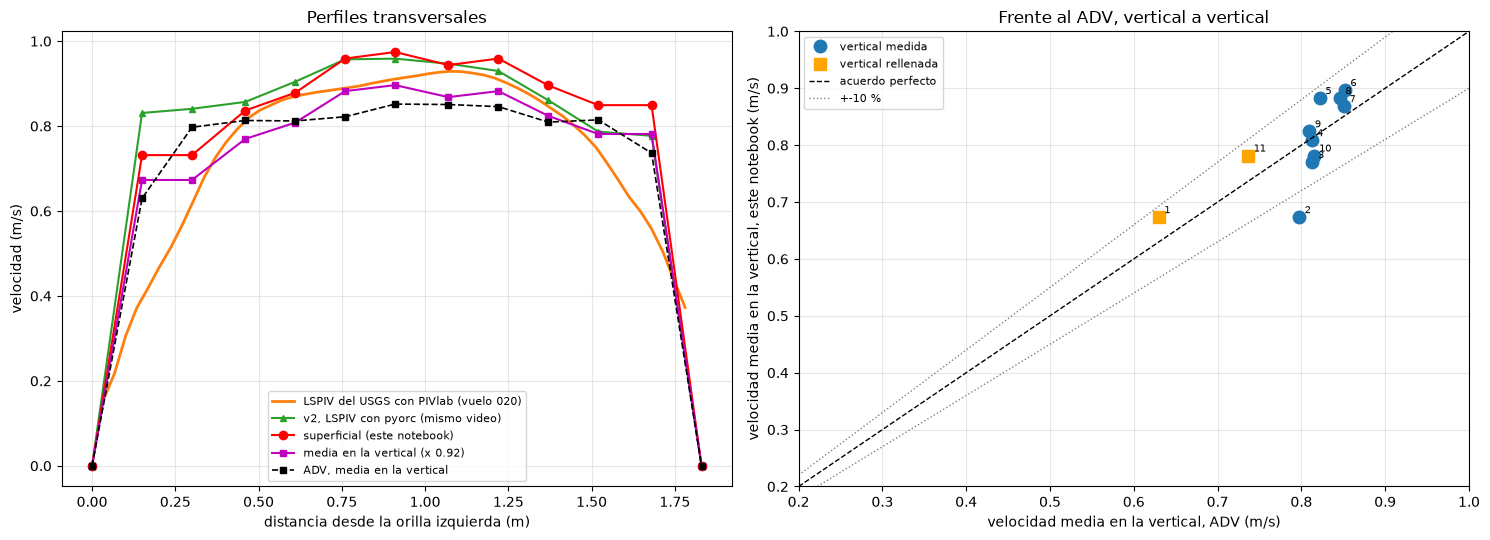

Sobre las 9 verticales medidas (se excluyen 2 rellenadas):
  Sesgo medio frente al ADV: -0.0035 m/s (-0.4 %)
  RMSE:                      0.0537 m/s
  v_corr implicito = 0.924  (el notebook uso 0.92; es un diagnostico, no una correccion)


,concepto,valor,unidad
0,Caudal (este notebook),1.448427,m3/s
1,Caudal aforo FlowTracker,1.436200,m3/s
2,Diferencia,0.851314,%
3,Verticales medidas,9.000000,de 11
4,Verticales rellenadas,2.000000,de 11
5,Sesgo frente al ADV (verticales medidas),-0.003472,m/s
6,v_corr usado,0.920000,-
7,v_corr implicito segun el ADV,0.923892,-


In [13]:
from scipy.io import loadmat

mat = loadmat(str(ARCHIVO_PIV_USGS))
# u_mean y v_mean en m/s; y_ground es la coordenada transversal. Se promedia a lo largo del canal.
perfil_usgs = np.hypot(mat["u_mean"], mat["v_mean"]).mean(axis=1)
y_usgs = mat["y_ground"][:, 0]
orden_y = np.argsort(y_usgs)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]
ax.plot(y_usgs[orden_y], perfil_usgs[orden_y], "-", color="tab:orange", lw=2,
        label="LSPIV del USGS con PIVlab (vuelo 020)")
if perfil_v2 is not None:                                                            # [v3]
    ax.plot(perfil_v2["s_m"], perfil_v2["v_sup_usada_ms"], "-^", color="tab:green", ms=5,
            label="v2, LSPIV con pyorc (mismo video)")
ax.plot(s_transecto, v_eff, "r-o", ms=6, label="superficial (este notebook)")
ax.plot(s_transecto, v_media_vertical, "m-s", ms=5, label=f"media en la vertical (x {V_CORR})")
ax.plot(s_transecto, V_ADV, "ks--", ms=5, lw=1.2, label="ADV, media en la vertical")
ax.set_xlabel("distancia desde la orilla izquierda (m)")
ax.set_ylabel("velocidad (m/s)")
ax.set_title("Perfiles transversales")
ax.grid(alpha=0.3); ax.legend(fontsize=8)

ax = axes[1]
interior = ~ES_CONTORNO
med = interior & medida
rel = interior & ~medida
ax.plot(V_ADV[med], v_media_vertical[med], "o", ms=9, color="tab:blue", label="vertical medida")
ax.plot(V_ADV[rel], v_media_vertical[rel], "s", ms=9, color="orange", label="vertical rellenada")
lim = [0.2, 1.0]
ax.plot(lim, lim, "k--", lw=1, label="acuerdo perfecto")
ax.plot(lim, [1.1 * v for v in lim], ":", color="gray", lw=1, label="+-10 %")
ax.plot(lim, [0.9 * v for v in lim], ":", color="gray", lw=1)
for i in np.where(interior)[0]:
    ax.annotate(str(i), (V_ADV[i], v_media_vertical[i]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("velocidad media en la vertical, ADV (m/s)")
ax.set_ylabel("velocidad media en la vertical, este notebook (m/s)")
ax.set_title("Frente al ADV, vertical a vertical")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(DIR_SALIDA / "fig8_comparacion.png", dpi=110, bbox_inches="tight")
plt.show()

# Las estadisticas se calculan solo sobre las verticales medidas: meter las rellenadas mediria
# el relleno, no el metodo.
sesgo = float(np.mean(v_media_vertical[med] - V_ADV[med]))
rmse = float(np.sqrt(np.mean((v_media_vertical[med] - V_ADV[med]) ** 2)))
v_corr_implicito = float(V_ADV[med].mean() / v_eff[med].mean())
print(f"Sobre las {int(med.sum())} verticales medidas (se excluyen {int(rel.sum())} rellenadas):")
print(f"  Sesgo medio frente al ADV: {sesgo:+.4f} m/s ({100 * sesgo / V_ADV[med].mean():+.1f} %)")
print(f"  RMSE:                      {rmse:.4f} m/s")
print(f"  v_corr implicito = {v_corr_implicito:.3f}  (el notebook uso {V_CORR}; es un "
      "diagnostico, no una correccion)")

resumen = pd.DataFrame([
    dict(concepto="Caudal (este notebook)", valor=Q_VIDEO, unidad="m3/s"),
    dict(concepto="Caudal aforo FlowTracker", valor=Q_AFORO, unidad="m3/s"),
    dict(concepto="Diferencia", valor=error_rel, unidad="%"),
    dict(concepto="Verticales medidas", valor=int(med.sum()), unidad="de 11"),
    dict(concepto="Verticales rellenadas", valor=int(rel.sum()), unidad="de 11"),
    dict(concepto="Sesgo frente al ADV (verticales medidas)", valor=sesgo, unidad="m/s"),
    dict(concepto="v_corr usado", valor=V_CORR, unidad="-"),
    dict(concepto="v_corr implicito segun el ADV", valor=v_corr_implicito, unidad="-"),
])
resumen.to_csv(SALIDA_RESUMEN, index=False)
resumen

---
## Archivos generados

Todo queda en `salidas/`, sin tocar los datos de entrada.

In [14]:
print(f"Contenido de {DIR_SALIDA}:\n")
for archivo in sorted(DIR_SALIDA.iterdir()):
    # st_size da el tamano en bytes; se divide entre 1024 para mostrarlo en KiB.
    print(f"  {archivo.name:<34} {archivo.stat().st_size / 1024:>10.1f} KiB")

Contenido de salidas:

  benchmark_recursos.csv                    0.3 KiB
  caudal_resumen.csv                        0.3 KiB
  config.json                               0.5 KiB
  fig1_fotograma.png                      652.4 KiB
  fig2_puntos_control.png                1518.5 KiB
  fig3_lineas_busqueda.png                657.7 KiB
  fig4_sti.png                            916.4 KiB
  fig5_perfil_transecto.png               101.4 KiB
  fig6_mapa_velocidades.png               438.2 KiB
  fig7_recursos.png                        26.3 KiB
  fig8_comparacion.png                    138.3 KiB
  perfil_velocidades.csv                    1.2 KiB
  sti_crudo.npy                          1967.9 KiB


---
## Lectura del resultado

**Lo que muestra el cambio de algoritmo.** Con el mismo video, la misma escala, la misma seccion y el
mismo `V_CORR`, LSPIV (v2) y STIV (v3) dan perfiles y caudales muy parecidos: la diferencia entre
ambos es menor que la incertidumbre del aforo. El coste no se parece en nada: STIV no guarda nunca
mas de un fotograma en memoria.

**Donde se va el error**, igual que en la v2: las verticales junto a los muros (aqui las rechaza la
coherencia y se interpolan), `V_CORR` y la escala.

## Limitaciones conocidas

1. **Las verticales contiguas a los muros son relleno**, no medida: la coherencia las rechaza y se
   interpolan linealmente.
2. **`V_CORR` no es medible en la imagen.**
3. **La escala cuelga de dos filas de pixeles.**
4. **Sin correccion de distorsion de lente**: lineas limitadas a las columnas 600-3400.
5. **El convenio de area**: se replica la seccion mid-section del CSV.
6. **STIV mide una sola componente**: supone flujo unidireccional a lo largo de la linea. Aqui la
   hipotesis es solida (canal recto), pero no en un cauce con recirculaciones.
7. **Vista cenital**: se muestrea sobre la imagen sin ortorrectificar, lo que solo vale porque la
   camara mira hacia abajo. Con una camara oblicua habria que rectificar antes (es la v4).